# Обыкновенные дифференциальные уравнения. Практика 3. Краевые задачи
Задачи для самостоятельного решения из `Дифференциальные уравнения. Практика 3.pdf`.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.linalg import solve_banded
from scipy.optimize import brentq

def bvp_shoot(f,a,b,alpha,beta,s_bracket=(-20,20),n_out=101):
    '''Метод стрельбы для y''=f(x,y,y'), y(a)=alpha, y(b)=beta.'''
    rhs = lambda x,v:[v[1],f(x,v[0],v[1])]
    def F(s):
        return solve_ivp(rhs,[a,b],[alpha,s],rtol=1e-10,atol=1e-12).y[0,-1]-beta
    s = brentq(F,*s_bracket,xtol=1e-12)
    xs = np.linspace(a,b,n_out)
    sol = solve_ivp(rhs,[a,b],[alpha,s],t_eval=xs,rtol=1e-10,atol=1e-12)
    return sol.t,sol.y[0],s

def bvp_fd(r,a,b,alpha,beta,N):
    '''Конечные разности для y''=r(x) с условиями Дирихле, N — число интервалов.'''
    x = np.linspace(a,b,N+1); h = (b-a)/N
    ab = np.zeros((3,N-1))
    ab[0,1:] = 1/h**2; ab[1,:] = -2/h**2; ab[2,:-1] = 1/h**2
    d = r(x[1:-1]).astype(float)
    d[0] -= alpha/h**2; d[-1] -= beta/h**2
    return x,np.r_[alpha,solve_banded((1,1),ab,d),beta]

def thomas(a,b,c,d):
    '''Метод прогонки: a — поддиагональ, b — диагональ, c — наддиагональ.'''
    n = len(d); cs,ds = np.zeros(n),np.zeros(n)
    cs[0],ds[0] = c[0]/b[0],d[0]/b[0]
    for i in range(1,n):
        m = b[i]-a[i]*cs[i-1]
        cs[i] = c[i]/m if i<n-1 else 0.
        ds[i] = (d[i]-a[i]*ds[i-1])/m
    y = np.zeros(n); y[-1] = ds[-1]
    for i in range(n-2,-1,-1):
        y[i] = ds[i]-cs[i]*y[i+1]
    return y

## Блок А. Аналитический эталон
Интегрируем дважды и подбираем постоянные.

**А1.** $y''=-2$, $y(0)=y(1)=0$. $\ y=-x^2+C_1x+C_2$, $C_2=0$, $C_1=1$: $\boxed{y=x(1-x)}$.

**А2.** $y''=6x$, $y(0)=0$, $y(1)=1$. $\ y=x^3+C_1x+C_2$, $C_1=C_2=0$: $\boxed{y=x^3}$.

**А3.** $y''=e^{-x}$, $y(0)=y(1)=0$. $\ y=e^{-x}+C_1x+C_2$. Из $y(0)=0$ следует $C_2=-1$, из $y(1)=0$ следует $C_1=1-e^{-1}$: $\boxed{y=e^{-x}+(1-e^{-1})x-1}$.

**А4.** $y''=2$, $y(0)=1$, $y(1)=2$: $\boxed{y=x^2+1}$.

**А5.** $y''=-\sin x$, $y(0)=y(1)=0$. $\ y=\sin x+C_1x+C_2$, $C_2=0$, $C_1=-\sin1$: $\boxed{y=\sin x-x\sin1}$.

In [2]:
X = sp.symbols('x')
sols = {'А1':(X*(1-X),-2,0,0),'А2':(X**3,6*X,0,1),'А3':(sp.exp(-X)+(1-sp.exp(-1))*X-1,sp.exp(-X),0,0),'А4':(X**2+1,2,1,2),'А5':(sp.sin(X)-X*sp.sin(1),-sp.sin(X),0,0)}
for nm,(y,r,a,b) in sols.items():
    assert sp.simplify(sp.diff(y,X,2)-r)==0 and sp.simplify(y.subs(X,0)-a)==0 and sp.simplify(y.subs(X,1)-b)==0
    print(nm,'проверено')
ex = {
 'x(1-x)/2':lambda x:x*(1-x)/2,'x(1-x)':lambda x:x*(1-x),'x^3':lambda x:x**3,'x^2+1':lambda x:x**2+1,
 'sin':lambda x:np.sin(x)-x*np.sin(1),'(x-x^3)/6':lambda x:(x-x**3)/6,'e^x':np.exp}

А1 проверено
А2 проверено
А3 проверено
А4 проверено
А5 проверено


## Блок Б. Метод стрельбы
Заменяем неизвестное $y'(0)$ параметром $s$ и ищем корень $F(s)=y(1;s)-\beta=0$.

*В листке для Б1 и В1 указано «сравнить с А1», но А1 имеет правую часть $-2$, а Б1 — $-1$. Для $y''=-1$ точное решение равно $x(1-x)/2$, то есть половине решения А1. С ним и сравниваем.*

Точные решения остальных задач: Б3: $y''=-x$, $y=(x-x^3)/6$. Б4: $y''=y$, $y(0)=1$, $y(1)=e$, $y=e^x$.

Б1: s=y'(0)=0.50000000, макс. ошибка 2.22e-16
Б2: s=y'(0)=1.00000000, макс. ошибка 2.50e-16
Б3: s=y'(0)=0.16666667, макс. ошибка 2.19e-15
Б4: s=y'(0)=1.00000000, макс. ошибка 5.07e-11
Б5: s=y'(0)=0.15852902, макс. ошибка 5.16e-12


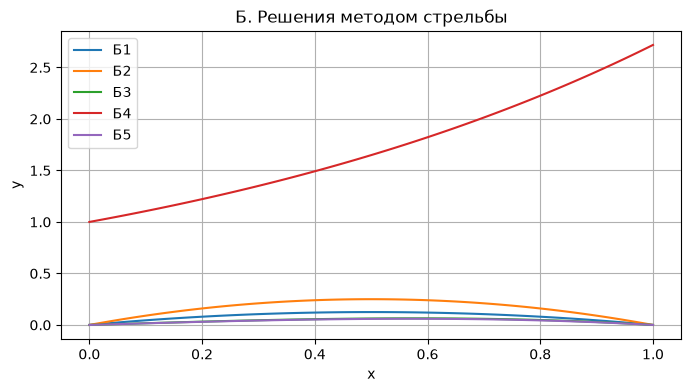

In [3]:
shoot_tasks = [('Б1',lambda x,y,p:-1.,0,0,ex['x(1-x)/2']),('Б2',lambda x,y,p:-2.,0,0,ex['x(1-x)']),
               ('Б3',lambda x,y,p:-x,0,0,ex['(x-x^3)/6']),('Б4',lambda x,y,p:y,1,np.e,ex['e^x']),
               ('Б5',lambda x,y,p:-np.sin(x),0,0,ex['sin'])]
fig,ax = plt.subplots(figsize=(8,4))
for nm,f,al,be,e in shoot_tasks:
    x,y,s = bvp_shoot(f,0,1,al,be)
    err = np.abs(y-e(x)).max(); print(f"{nm}: s=y'(0)={s:.8f}, макс. ошибка {err:.2e}")
    assert err<1e-7
    ax.plot(x,y,label=nm)
ax.legend(); ax.grid(True); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('Б. Решения методом стрельбы')
fig.savefig('fig/DE3_B.png',dpi=120,bbox_inches='tight'); plt.show()

## Блок В. Метод конечных разностей
$\dfrac{y_{i-1}-2y_i+y_{i+1}}{h^2}=r(x_i)$ при $N=10$. Для многочленов степени не выше $3$ схема точна, так как её погрешность равна $\dfrac{h^2}{12}y^{(4)}(\xi)$. Поэтому в В1–В4 ошибка на уровне округления, а в В5 ненулевая.

In [4]:
fd_tasks = [('В1',lambda x:-np.ones_like(x),0,0,ex['x(1-x)/2']),('В2',lambda x:-2*np.ones_like(x),0,0,ex['x(1-x)']),
            ('В3',lambda x:6*x,0,1,ex['x^3']),('В4',lambda x:2*np.ones_like(x),1,2,ex['x^2+1']),('В5',lambda x:-np.sin(x),0,0,ex['sin'])]
for nm,r,al,be,e in fd_tasks:
    x,y = bvp_fd(r,0,1,al,be,10); err = np.abs(y-e(x)).max(); print(f'{nm}: N=10, макс. ошибка {err:.2e}')
    assert err<(1e-4 if nm=='В5' else 1e-12)

В1: N=10, макс. ошибка 2.78e-17
В2: N=10, макс. ошибка 5.55e-17
В3: N=10, макс. ошибка 3.33e-16
В4: N=10, макс. ошибка 6.66e-16
В5: N=10, макс. ошибка 4.98e-05


## Блок Г. Прогонка
**Г1.** Для $y''=-1$, $y(0)=y(1)=0$, $N=10$, $h=0{,}1$. Схема $-y_{i-1}+2y_i-y_{i+1}=h^2=0{,}01$ при $i=1,\dots,9$; $y_0=y_{10}=0$. Получаем систему с трёхдиагональной матрицей $9\times9$: на диагонали $2$, рядом с диагональю $-1$, правая часть $0{,}01$:
$$\begin{pmatrix}2&-1\\-1&2&-1\\&\ddots&\ddots&\ddots\\&&-1&2\end{pmatrix}\begin{pmatrix}y_1\\y_2\\\vdots\\y_9\end{pmatrix}=\begin{pmatrix}0{,}01\\0{,}01\\\vdots\\0{,}01\end{pmatrix}.$$

In [5]:
m = 9
a,b,c,d = -np.ones(m),2*np.ones(m),-np.ones(m),.01*np.ones(m)
A = np.diag(b)+np.diag(a[1:],-1)+np.diag(c[:-1],1); print(A.astype(int))
y1 = thomas(a,b,c,d); y2 = np.linalg.solve(A,d)
x = np.linspace(.1,.9,9)
print('Г2. thomas:',np.round(y1,6)); print('Г2. solve :',np.round(y2,6)); print('разность:',np.abs(y1-y2).max(),' ошибка от точного:',np.abs(y1-x*(1-x)/2).max())
assert np.allclose(y1,y2) and np.allclose(y1,x*(1-x)/2)

[[ 2 -1  0  0  0  0  0  0  0]
 [-1  2 -1  0  0  0  0  0  0]
 [ 0 -1  2 -1  0  0  0  0  0]
 [ 0  0 -1  2 -1  0  0  0  0]
 [ 0  0  0 -1  2 -1  0  0  0]
 [ 0  0  0  0 -1  2 -1  0  0]
 [ 0  0  0  0  0 -1  2 -1  0]
 [ 0  0  0  0  0  0 -1  2 -1]
 [ 0  0  0  0  0  0  0 -1  2]]
Г2. thomas: [0.045 0.08  0.105 0.12  0.125 0.12  0.105 0.08  0.045]
Г2. solve : [0.045 0.08  0.105 0.12  0.125 0.12  0.105 0.08  0.045]
разность: 1.3877787807814457e-17  ошибка от точного: 4.163336342344337e-17


**Г3.** Время решения на $N=1000$. Измерения усреднены по нескольким запускам, абсолютные значения зависят от компьютера.

In [6]:
def timed(fn,rep):
    t = time.perf_counter()
    for _ in range(rep): res = fn()
    return (time.perf_counter()-t)/rep,res

N = 999
a,b,c = -np.ones(N),2*np.ones(N),-np.ones(N); d = np.ones(N)/1000**2
ab = np.zeros((3,N)); ab[0,1:] = c[:-1]; ab[1] = b; ab[2,:-1] = a[1:]
A = np.diag(b)+np.diag(a[1:],-1)+np.diag(c[:-1],1)
t1,y1 = timed(lambda:thomas(a,b,c,d),20); t2,y2 = timed(lambda:solve_banded((1,1),ab,d),200); t3,y3 = timed(lambda:np.linalg.solve(A,d),20)
assert np.allclose(y1,y2) and np.allclose(y1,y3)
for nm,t in (('thomas (Python)',t1),('solve_banded',t2),('np.linalg.solve',t3)): print(f'{nm:18s}{t*1e3:9.3f} мс')

thomas (Python)       0.676 мс
solve_banded          0.027 мс
np.linalg.solve      50.250 мс


**Вывод.** `solve_banded` быстрее всех: это та же прогонка $O(N)$, но на компилированном коде. Собственная прогонка на Python тоже имеет сложность $O(N)$, но цикл интерпретатора делает её медленнее. `np.linalg.solve` имеет сложность $O(N^3)$ и не использует разреженность, поэтому при росте $N$ он проигрывает обоим.

## Блок Д. Сравнение методов
**Д1.** Задача $y''=-x$, $y(0)=y(1)=0$ при $N=10,50,100$.

N: [10, 50, 100]
стрельба: ['2.19e-15', '2.19e-15', '2.19e-15']
разности: ['1.39e-17', '1.46e-16', '1.73e-16']


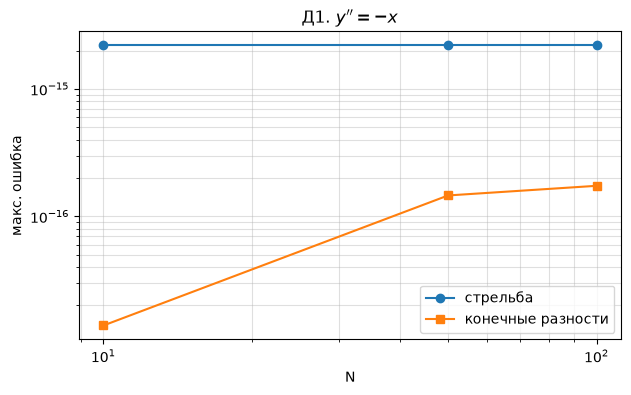

In [7]:
Ns = [10,50,100]; e = ex['(x-x^3)/6']; errS,errF = [],[]
for N in Ns:
    xs,ys,_ = bvp_shoot(lambda x,y,p:-x,0,1,0,0,n_out=N+1); errS.append(np.abs(ys-e(xs)).max())
    xf,yf = bvp_fd(lambda x:-x,0,1,0,0,N); errF.append(np.abs(yf-e(xf)).max())
print('N:',Ns); print('стрельба:',['%.2e'%v for v in errS]); print('разности:',['%.2e'%v for v in errF])
fig,ax = plt.subplots(figsize=(7,4))
ax.loglog(Ns,errS,'o-',label='стрельба'); ax.loglog(Ns,errF,'s-',label='конечные разности'); ax.set_xlabel('N'); ax.set_ylabel('макс. ошибка'); ax.grid(True,which='both',alpha=.4); ax.legend(); ax.set_title("Д1. $y''=-x$")
fig.savefig('fig/DE3_D1.png',dpi=120,bbox_inches='tight'); plt.show()

**Что видно.** Точное решение кубическое, поэтому конечные разности дают его точно: ошибка равна только ошибке округления и растёт с $N$. Для стрельбы $N$ — только число точек вывода, ошибку определяет допуск интегратора.

**Д2.** По этой причине на задаче из Д1 порядок метода определить нельзя: наклон прямой показал бы только рост ошибок округления. Порядок определяем на $y''=-\sin x$, где решение не многочлен.

наклон по h: 1.999


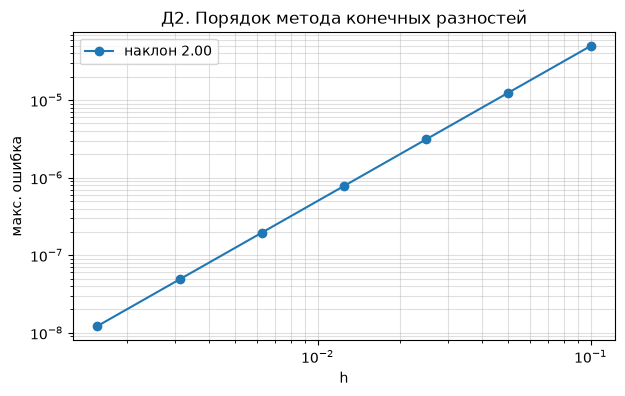

In [8]:
Ns2 = np.array([10,20,40,80,160,320,640]); errs = []
for N in Ns2:
    x,y = bvp_fd(lambda x:-np.sin(x),0,1,0,0,int(N)); errs.append(np.abs(y-ex['sin'](x)).max())
slope = np.polyfit(np.log(1/Ns2),np.log(errs),1)[0]; print(f'наклон по h: {slope:.3f}'); assert abs(slope-2)<.05
fig,ax = plt.subplots(figsize=(7,4)); ax.loglog(1/Ns2,errs,'o-',label=f'наклон {slope:.2f}'); ax.set_xlabel('h'); ax.set_ylabel('макс. ошибка'); ax.grid(True,which='both',alpha=.4); ax.legend(); ax.set_title('Д2. Порядок метода конечных разностей')
fig.savefig('fig/DE3_D2.png',dpi=120,bbox_inches='tight'); plt.show()

**Ответ Д2:** второй порядок, $O(h^2)$.

**Д3.** Для $y''=-\sin x$ сравним ошибки при $N=100$.

In [9]:
xs,ys,_ = bvp_shoot(lambda x,y,p:-np.sin(x),0,1,0,0,n_out=101); es = np.abs(ys-ex['sin'](xs)).max()
xf,yf = bvp_fd(lambda x:-np.sin(x),0,1,0,0,100); ef = np.abs(yf-ex['sin'](xf)).max()
print(f'стрельба: {es:.2e}, конечные разности: {ef:.2e}'); assert es<ef
h = .01; print(f'оценка h²/12·max|y⁗|·(1/8): {h*h/12*np.sin(1)/8:.2e}')

стрельба: 5.16e-12, конечные разности: 5.00e-07
оценка h²/12·max|y⁗|·(1/8): 8.77e-07


**Почему стрельба точнее.** Стрельба использует адаптивный метод RK45 с жёстким допуском (`rtol=1e-10`). Её ошибка определяется допуском, а не числом $N$. Конечные разности имеют второй порядок: при $h=0{,}01$ ошибка порядка $h^2/12\cdot|y^{(4)}|\cdot\tfrac18\approx10^{-6}$. Измеренная ошибка $5\cdot10^{-7}$ того же порядка. Чтобы получить ту же точность разностями, потребовался бы намного меньший шаг, и тогда уже росли бы ошибки округления.